In [5]:
import re
import spacy
import numpy as np
import pandas as pd
from nltk.corpus import stopwords
from nltk.stem import SnowballStemmer
from sklearn.metrics.pairwise import cosine_similarity
import matplotlib.pyplot as plt
import seaborn as sns

# -----------------------------
# Pipeline di pre-elaborazione
# -----------------------------
class PipelineNotizia:
    def __init__(self, lingua='italian'):
        self.lingua = lingua
        self.nlp = spacy.load('it_core_news_sm' if lingua == 'italian' else 'en_core_web_sm')
        self.stemmer = SnowballStemmer(lingua)
        self.stop_words = set(stopwords.words(lingua))
        
    def normalizza_testo(self, testo):
        testo = re.sub(r'[^\w\sàèéìòù]', ' ', testo)
        testo = re.sub(r'\s+', ' ', testo).strip()
        return testo
    
    def tokenizza_e_lemmatizza(self, testo):
        doc = self.nlp(testo)
        tokens = []
        for token in doc:
            if not token.is_punct and not token.is_space and token.is_alpha:
                lemma = token.lemma_ if token.lemma_ != '-PRON-' else token.text
                tokens.append((token.text, lemma, token.pos_))
        return tokens
    
    def rimuovi_stop_words(self, tokens):
        return [lemma for (text, lemma, pos) in tokens if lemma.lower() not in self.stop_words]
    
    def processa_testo(self, testo):
        testo_norm = self.normalizza_testo(testo)
        tokens = self.tokenizza_e_lemmatizza(testo_norm)
        tokens_senza_stop = self.rimuovi_stop_words(tokens)
        tokens_filtrati = [lemma for (text, lemma, pos) in tokens if lemma in tokens_senza_stop and pos in ['NOUN', 'VERB']]
        return list(set(tokens_filtrati))

# -----------------------------
# Bag of Words (Unigram)
# -----------------------------
class BagOfWordsPipeline:
    def __init__(self, lingua='italian'):
        self.pipeline = PipelineNotizia(lingua)
        self.vocabolario = {}
        self.vocabolario_inverso = {}
        self.dimensione_vocab = 0
    
    def costruisci_vocabolario(self, documenti):
        self.documenti_tokenizzati = []
        tutte_parole = set()
        for doc in documenti:
            tokens = self.pipeline.processa_testo(doc)
            self.documenti_tokenizzati.append(tokens)
            tutte_parole.update(tokens)
        
        for i, parola in enumerate(sorted(tutte_parole)):
            self.vocabolario[parola] = i
            self.vocabolario_inverso[i] = parola
        self.dimensione_vocab = len(self.vocabolario)
    
    def documento_to_vettore(self, tokens):
        vettore = np.zeros(self.dimensione_vocab)
        for parola in tokens:
            if parola in self.vocabolario:
                indice = self.vocabolario[parola]
                vettore[indice] += 1
        return vettore
    
    def trasforma_documenti(self):
        self.matrice = np.array([self.documento_to_vettore(tokens) for tokens in self.documenti_tokenizzati])
        return self.matrice
    
    def similarita_coseno(self):
        self.similarita = cosine_similarity(self.matrice)
        return self.similarita
    
    def visualizza_heatmap_similarita(self):
        df_similarita = pd.DataFrame(
            self.similarita, 
            index=[f"Doc {i+1}" for i in range(len(self.documenti_tokenizzati))],
            columns=[f"Doc {i+1}" for i in range(len(self.documenti_tokenizzati))]
        )
        plt.figure(figsize=(8,6))
        sns.heatmap(df_similarita, annot=True, fmt=".2f", cmap='coolwarm', cbar_kws={'label': 'Cosine Similarity'})
        plt.title('Heatmap Similarità Coseno')
        plt.xlabel('Documenti')
        plt.ylabel('Documenti')
        plt.show()
    
    def run_pipeline(self, documenti):
        print("1️⃣ Testi tokenizzati:")
        self.costruisci_vocabolario(documenti)
        for i, tokens in enumerate(self.documenti_tokenizzati, 1):
            print(f"Doc {i}: {tokens}")
        
        print("\n2️⃣ Vocabolario:")
        print(sorted(self.vocabolario.keys()))
        
        print("\n3️⃣ Matrice Bag of Words:")
        matrice = self.trasforma_documenti()
        df_bow = pd.DataFrame(matrice, columns=list(self.vocabolario.keys()),
                              index=[f"Doc {i+1}" for i in range(len(documenti))])

        print("\n4️⃣ Heatmap della matrice Bag of Words:")
        self.visualizza_heatmap_bow()
        
        print("\n4️⃣ Heatmap della similarità coseno:")
        self.similarita_coseno()
        self.visualizza_heatmap_similarita()
        return self.documenti_tokenizzati, self.vocabolario, matrice, self.similarita


    def visualizza_heatmap_bow(self):
        df_bow = pd.DataFrame(
            self.matrice, 
            columns=list(self.vocabolario.keys()),
            index=[f"Doc {i+1}" for i in range(len(self.documenti_tokenizzati))]
        )
        plt.figure(figsize=(12,6))
        sns.heatmap(df_bow, annot=True, cmap='Blues', cbar_kws={'label': 'Frequenza'})
        plt.title('Heatmap Bag of Words')
        plt.xlabel('Parole')
        plt.ylabel('Documenti')
        plt.xticks(rotation=45)
        plt.show()

1️⃣ Testi tokenizzati:
Doc 1: ['cibo', 'servizio', 'ristorante']
Doc 2: ['cibo', 'buere', 'servizio']
Doc 3: ['trama', 'film', 'piacere']
Doc 4: ['consiglio', 'recitare']
Doc 5: ['giorno', 'rompere', 'comprare', 'prodotto']
Doc 6: ['rapporto', 'prezzo', 'qualità', 'prodotto']
Doc 7: ['viaggio', 'bagaglio', 'ritardo', 'caos']
Doc 8: ['viaggio', 'esperienza']
Doc 9: ['cuffia', 'qualità', 'suono']
Doc 10: ['cristallare', 'soddisfare']
Doc 11: ['usare', 'interfaccia', 'trovare']
Doc 12: ['friendly', 'interfaccia', 'principiante', 'user']

2️⃣ Vocabolario:
['bagaglio', 'buere', 'caos', 'cibo', 'comprare', 'consiglio', 'cristallare', 'cuffia', 'esperienza', 'film', 'friendly', 'giorno', 'interfaccia', 'piacere', 'prezzo', 'principiante', 'prodotto', 'qualità', 'rapporto', 'recitare', 'ristorante', 'ritardo', 'rompere', 'servizio', 'soddisfare', 'suono', 'trama', 'trovare', 'usare', 'user', 'viaggio']

3️⃣ Matrice Bag of Words:

4️⃣ Heatmap della matrice Bag of Words:


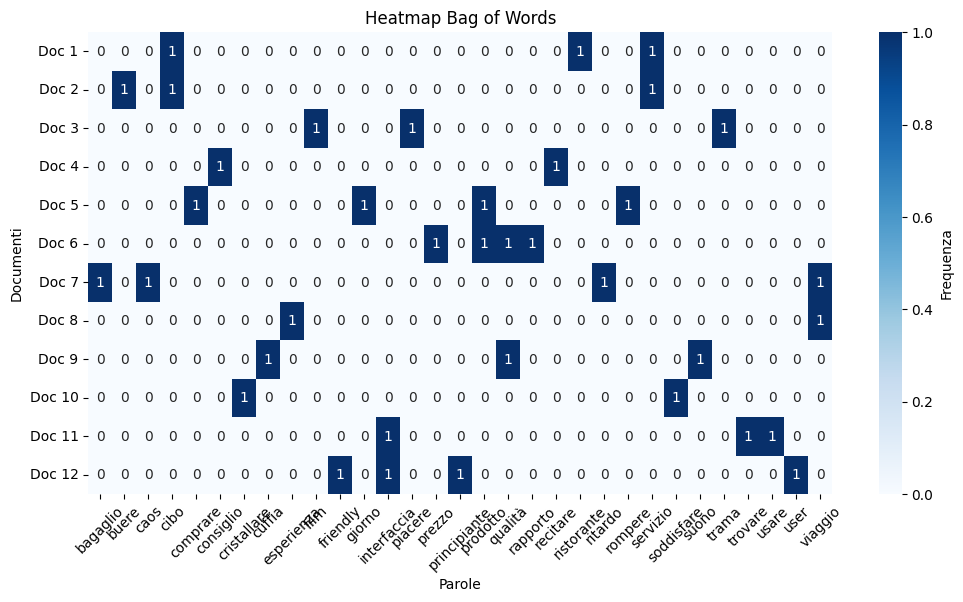


4️⃣ Heatmap della similarità coseno:


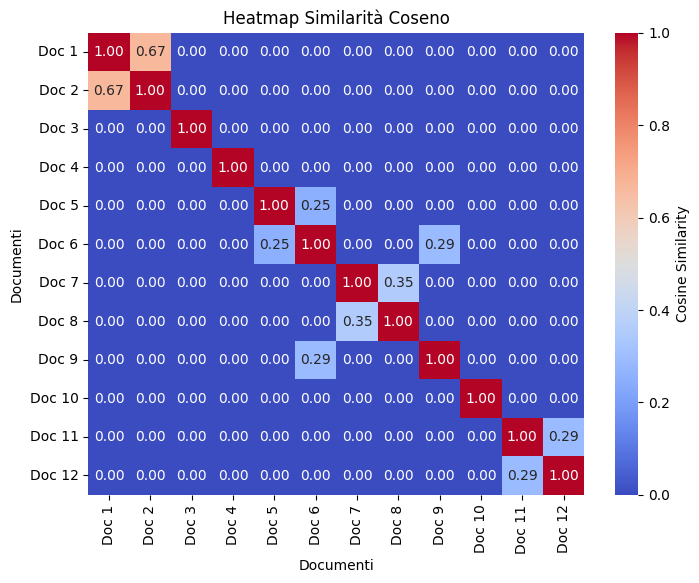

In [7]:
# -----------------------------
# Esempio d'uso
# -----------------------------
documenti_esempio = [
    "Il ristorante era fantastico, il servizio veloce e il cibo ottimo!",
    "Il servizio era lento, ma il cibo era buono.",
    "Non mi è piaciuto il film, la trama era prevedibile.",
    "Film emozionante e ben recitato — lo consiglio!",
    "Ho comprato questo prodotto, ma si è rotto dopo due giorni.",
    "Prodotto eccellente, rapporto qualità-prezzo incredibile.",
    "Il viaggio è stato stancante: ritardi, bagagli persi e caos.",
    "Che bella esperienza di viaggio, tutto perfetto e organizzato.",
    "La qualità del suono è buona, ma le cuffie sono scomode.",
    "Cuffie comode e suono cristallino; molto soddisfatto.",
    "Non ho trovato l'interfaccia intuitiva: difficile da usare.",
    "Interfaccia chiara e molto user-friendly, ottima per principianti."
]

pipeline = BagOfWordsPipeline(lingua='italian')
tokens, vocabolario, matrice, similarita = pipeline.run_pipeline(documenti_esempio)